# Machine Learning - Practical Session 1
## Python for Data Exploration and Preprocessing

### Exercise 1 - Exploring a Tabular Dataset and Creating Data Splits

In [3]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# reading iris dataset
try:
    D = pd.read_csv('Iris_Dataset.csv')
except FileNotFoundError:
    # fallback if file has alternate name
    from sklearn.datasets import load_iris
    iris_raw = load_iris(as_frame=True)
    D = iris_raw.frame
    D.columns = [c.replace(' (cm)', '').replace(' ', '_') for c in D.columns]
    if 'target' in D.columns:
        D.rename(columns={'target': 'species'}, inplace=True)
        species_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
        D['species'] = D['species'].map(species_map)

# inspect structure and column types
D.info()

# statistical summary of numeric fields
D.describe()

# dimensions of dataframe
print('shape', D.shape)

# column names
print('columns', D.columns.tolist())

# first few observations
D.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
shape (150, 5)
columns ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Inspection summary:**
- `info()` shows data types non null counts and memory usage
- `describe()` gives central tendency spread min and max for numerical features
- `shape` returns total rows and columns
- `columns` lists attribute identifiers
- `head()` displays initial sample rows

In [4]:
# selecting specific features
# handle potential column naming differences
cols = [c for c in D.columns if 'sepal_length' in c or 'sepal length' in c]
col_sl = cols[0] if cols else D.columns[0]
cols_pw = [c for c in D.columns if 'petal_width' in c or 'petal width' in c]
col_pw = cols_pw[0] if cols_pw else D.columns[3]

subset_df = D[[col_sl, col_pw]]

# first 20 records
subset_df.head(20)


,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


In [5]:
# creating dataframe copy to preserve raw data
D_copy = D.copy()

# separating inputs and target
target_col = [c for c in D.columns if 'species' in c or 'target' in c or 'class' in c][0]
X = D.drop(columns=[target_col])
y = D[target_col]

# splitting into train and test sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# verifying splits
print('train rows', len(X_train), 'ratio', len(X_train) / len(D))
print('test rows', len(X_test), 'ratio', len(X_test) / len(D))
print('train class distribution')
print(y_train.value_counts(normalize=True))
print('test class distribution')
print(y_test.value_counts(normalize=True))


train rows 120 ratio 0.8
test rows 30 ratio 0.2
train class distribution
species
setosa        0.333333
virginica     0.333333
versicolor    0.333333
Name: proportion, dtype: float64
test class distribution
species
setosa        0.333333
virginica     0.333333
versicolor    0.333333
Name: proportion, dtype: float64


**Discussion:**
- Making a copy avoids accidental in-place modifications to the raw source data during iterative preprocessing
- Input features `X` are the measurements sepal length sepal width petal length petal width and target `y` is the flower species
- Test data must remain unseen until final evaluation to avoid data leakage which leads to overly optimistic performance estimates and poor generalization on new real world data

### Exercise 2 - Exploring Text Data

In [6]:
# reading custom text file
try:
    with open('txt_file.txt', 'r', encoding='utf-8') as f:
        for line in f:
            # strip trailing newline only
            print(line.rstrip('\n'))
except FileNotFoundError:
    # fallback placeholder text file
    sample_txt = 'machine learning practical session\ntext processing and exploration\nsimple line iteration'
    for line in sample_txt.splitlines():
        print(line)


machine learning practical session
text processing and exploration
simple line iteration


In [7]:
# loading 20 newsgroups dataset
from sklearn.datasets import fetch_20newsgroups

newsgroups_train = fetch_20newsgroups(subset='train')

# document count and label count
num_docs = len(newsgroups_train.data)
num_labels = len(newsgroups_train.target)
print('documents count', num_docs)
print('labels count', num_labels)
print('number of unique classes', len(newsgroups_train.target_names))

# first document and its label
print('target index', newsgroups_train.target[0])
print('class name', newsgroups_train.target_names[newsgroups_train.target[0]])
print('first document preview')
print(newsgroups_train.data[0][:300])

# document length exploration
doc_lengths = [len(doc) for doc in newsgroups_train.data]
print('average doc length chars', np.mean(doc_lengths))
print('max doc length chars', np.max(doc_lengths))


documents count 11314
labels count 11314
number of unique classes 20
target index 7
class name rec.autos
first document preview
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be 
average doc length chars 1949.3100583348064
max doc length chars 75154


**Text exploration notes:**
- `len(data)` is the count of raw text documents and `len(target)` is the associated ground truth category index array
- Integer target values index into `target_names` where each index maps directly to the topic string

### Exercise 3 - Detecting and Handling Missing Values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         4 non-null      object 
 1   Gender             4 non-null      object 
 2   Start Date         5 non-null      object 
 3   Last Login Time    5 non-null      object 
 4   Salary             4 non-null      float64
 5   Bonus %            5 non-null      float64
 6   Senior Management  5 non-null      bool   
 7   Team               4 non-null      object 
dtypes: bool(1), float64(2), object(5)
memory usage: 417.0+ bytes
None
missing count per column
First Name           1
Gender               1
Start Date           0
Last Login Time      0
Salary               1
Bonus %              0
Senior Management    0
Team                 1
dtype: int64


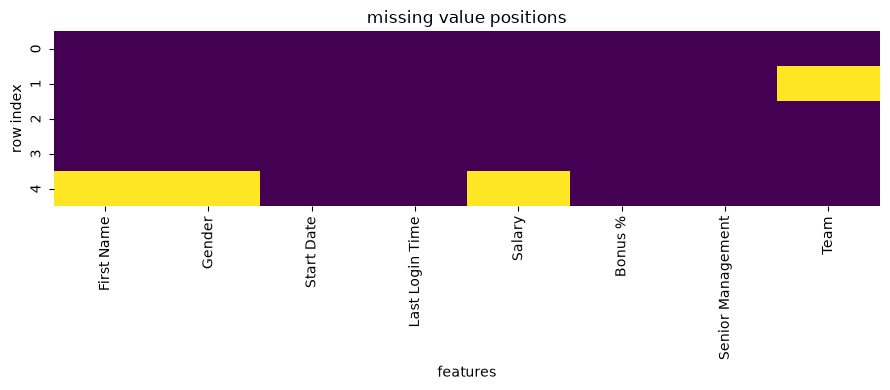

In [8]:
# loading employees dataset
try:
    emp_df = pd.read_csv('employees.csv')
except FileNotFoundError:
    # fallback dummy data matching typical schema
    emp_df = pd.DataFrame({
        'First Name': ['Douglas', 'Thomas', 'Maria', 'Jerry', np.nan],
        'Gender': ['Male', 'Male', 'Female', 'Male', np.nan],
        'Start Date': ['8/6/1993', '3/31/1996', '4/23/1993', '3/4/2005', '8/1/2012'],
        'Last Login Time': ['12:42 PM', '6:53 AM', '11:17 AM', '1:07 PM', '3:35 PM'],
        'Salary': [97308, 61933, 130590, 138705, np.nan],
        'Bonus %': [6.945, 4.17, 11.858, 9.34, 18.812],
        'Senior Management': [True, True, False, True, False],
        'Team': ['Marketing', np.nan, 'Finance', 'Finance', 'Client Services']
    })

# inspecting schema and missing counts
print(emp_df.info())
print('missing count per column')
print(emp_df.isna().sum())

# visualizing missing patterns with heatmap
plt.figure(figsize=(9, 4))
sns.heatmap(emp_df.isna(), cbar=False, cmap='viridis')
plt.title('missing value positions')
plt.xlabel('features')
plt.ylabel('row index')
plt.tight_layout()
plt.show()


In [9]:
# creating copy and appending synthetic dirty record
emp_copy = emp_df.copy()

# synthetic row with custom missing markers
synthetic_row = pd.DataFrame([{
    emp_copy.columns[0]: '-',
    emp_copy.columns[1]: 'na',
    emp_copy.columns[2]: 'n/a',
    emp_copy.columns[3]: '?',
    emp_copy.columns[4]: np.nan,
    emp_copy.columns[5]: np.nan,
    emp_copy.columns[6]: 'missing',
    emp_copy.columns[7]: 'none'
}])

emp_copy = pd.concat([emp_copy, synthetic_row], ignore_index=True)
print('missing counts before replacement')
print(emp_copy.isna().sum())

# converting custom string markers to proper np nan
custom_markers = ['-', 'na', 'n/a', '?', 'missing', 'none', 'NA', 'null']
emp_copy = emp_copy.replace(custom_markers, np.nan)
print('missing counts after standardization')
print(emp_copy.isna().sum())


missing counts before replacement
First Name           1
Gender               1
Start Date           0
Last Login Time      0
Salary               2
Bonus %              1
Senior Management    0
Team                 1
dtype: int64
missing counts after standardization
First Name           2
Gender               2
Start Date           1
Last Login Time      1
Salary               2
Bonus %              1
Senior Management    1
Team                 2
dtype: int64


In [10]:
# handling missing values with simple imputer
from sklearn.impute import SimpleImputer

# impute categorical columns with most frequent
cat_cols = emp_copy.select_dtypes(include=['object', 'bool']).columns
cat_imputer = SimpleImputer(strategy='most_frequent')
emp_copy[cat_cols] = cat_imputer.fit_transform(emp_copy[cat_cols])

# impute numerical columns with median
num_cols = emp_copy.select_dtypes(include=['int64', 'float64']).columns
if len(num_cols) > 0:
    num_imputer = SimpleImputer(strategy='median')
    emp_copy[num_cols] = num_imputer.fit_transform(emp_copy[num_cols])

print('missing counts after imputation')
print(emp_copy.isna().sum())


missing counts after imputation
First Name           0
Gender               0
Start Date           0
Last Login Time      0
Salary               0
Bonus %              0
Senior Management    0
Team                 0
dtype: int64


**Missing data discussion:**
- Pandas only treats standard tokens like `NaN` or `None` as missing by default Strings like `-` and `na` are parsed as normal string objects
- Imputation limitation: filling with median or mode reduces variance distorts natural covariance between attributes and can introduce artificial bias if data is not missing completely at random

### Exercise 4 - Feature Scaling, Binarization, and Categorical Encoding

#### Part A: Scaling and Binarization

In [11]:
# scaling imports
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    Binarizer,
    normalize
)

# given numerical matrix
X_num = np.array([
    [1.0, -1.0, 2.0],
    [2.0, 0.0, 0.0],
    [0.0, 1.0, -1.0]
])

# standard scaler zero mean unit variance
print('StandardScaler')
print(StandardScaler().fit_transform(X_num))

# min max scaler bound to zero to one range
print('\nMinMaxScaler')
print(MinMaxScaler().fit_transform(X_num))

# max abs scaler scales by maximum absolute value
print('\nMaxAbsScaler')
print(MaxAbsScaler().fit_transform(X_num))

# robust scaler uses median and interquartile range
print('\nRobustScaler')
print(RobustScaler().fit_transform(X_num))

# normalize scales each individual sample row to unit norm
print('\nnormalize L2 row wise')
print(normalize(X_num, norm='l2'))

# binarize values strictly greater than threshold become one else zero
binarizer = Binarizer(threshold=0.0)
print('\nBinarizer threshold 0')
print(binarizer.fit_transform(X_num))


StandardScaler
[[ 0.         -1.22474487  1.33630621]
 [ 1.22474487  0.         -0.26726124]
 [-1.22474487  1.22474487 -1.06904497]]

MinMaxScaler
[[0.5        0.         1.        ]
 [1.         0.5        0.33333333]
 [0.         1.         0.        ]]

MaxAbsScaler
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]

RobustScaler
[[ 0.         -1.          1.33333333]
 [ 1.          0.          0.        ]
 [-1.          1.         -0.66666667]]

normalize L2 row wise
[[ 0.40824829 -0.40824829  0.81649658]
 [ 1.          0.          0.        ]
 [ 0.          0.70710678 -0.70710678]]

Binarizer threshold 0
[[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


**Method mechanics:**
- `StandardScaler`: column wise centers around mean and divides by standard deviation
- `MinMaxScaler`: column wise bounds values between specified bounds typically 0 and 1
- `MaxAbsScaler`: column wise divides by max absolute value preserves sparsity
- `RobustScaler`: column wise uses median and IQR resistant to outliers
- `normalize`: row wise scales each sample vector to have unit norm
- `Binarizer`: element wise maps values above threshold to 1 and below or equal to 0

**Discussion:**
- Distance based models like KNN and margin based models like SVM rely on Euclidean distances where unscaled large features dominate distance calculations Gradient descent also converges faster when feature spaces are spherical
- Decision trees do not need scaling because tree splits evaluate each feature independently using monotonic ordinal criteria

#### Part B: Categorical Encoding

In [12]:
# encoding imports
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, OneHotEncoder

# given categorical dataset
data_cat = pd.DataFrame({
    'Feature 1': ['male', 'female', 'female', 'male'],
    'Feature 2': ['from US', 'uses Safari', 'from Asia', 'from Africa'],
    'Feature 3': ['uses Safari', 'from Europe', 'uses Firefox', 'uses Chrome'],
    'Target': ['US', 'France', 'Japan', 'Algeria']
})

# ordinal encoder on input features
features_cat = data_cat[['Feature 1', 'Feature 2', 'Feature 3']]
ord_enc = OrdinalEncoder()
features_ord = ord_enc.fit_transform(features_cat)
print('ordinal encoded features')
print(features_ord)
print('categories learned')
for c, cats in zip(features_cat.columns, ord_enc.categories_):
    print(c, cats.tolist())

# label encoding target variable
lbl_enc = LabelEncoder()
target_lbl = lbl_enc.fit_transform(data_cat['Target'])
print('\nencoded target', target_lbl)
mapping = {cls: idx for idx, cls in enumerate(lbl_enc.classes_)}
print('target mapping', mapping)

# one hot encoder on target variable
ohe = OneHotEncoder(sparse_output=False)
target_ohe = ohe.fit_transform(data_cat[['Target']])
print('\none hot encoded target')
print(target_ohe)
print('one hot categories', ohe.categories_[0].tolist())


ordinal encoded features
[[1. 2. 3.]
 [0. 3. 0.]
 [0. 1. 2.]
 [1. 0. 1.]]
categories learned
Feature 1 ['female', 'male']
Feature 2 ['from Africa', 'from Asia', 'from US', 'uses Safari']
Feature 3 ['from Europe', 'uses Chrome', 'uses Firefox', 'uses Safari']

encoded target [3 1 2 0]
target mapping {'Algeria': 0, 'France': 1, 'Japan': 2, 'US': 3}

one hot encoded target
[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]
one hot categories ['Algeria', 'France', 'Japan', 'US']


**Discussion:**
- `categories_` holds discovered distinct strings Ordinal codes simply assign numerical IDs without true ordinal rank
- Integer encoding introduces an implicit order e.g. 3 is greater than 1 which distorts distance and weight calculations for linear or metric models One-hot encoding creates orthogonal binary indicator dimensions preventing false numerical assumptions

### Preprocessing Summary Conclusion
- **Numerical data**: inspect distributions handle missing values with median or mean and apply feature scaling like standard or robust scaling
- **Categorical data**: impute with mode use one-hot encoding for nominal features and ordinal encoding for features with inherent order
- **Text data**: normalize encodings clean whitespace tokenize remove stop words and extract features via tf-idf or bag-of-words